# Phase 3 — External Capabilities

* Integrate Weather MCP.
* Integrate trvl MCP.
* Integrate TicketLens MCP.
* Evaluate the impact of external data on recommendations.

In [7]:
# Imports and environment setup

import os
import json
import uuid
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display, Markdown
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, ToolMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain.tools import tool, ToolRuntime
from langgraph.types import Command
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langchain_mcp_adapters.client import MultiServerMCPClient
from pydantic import BaseModel, Field

load_dotenv(override=True)

True

## IMPORTANT: Adjustment for Windows

The following adjustment is needed when running MCP servers via stdio inside a Jupyter notebook on Windows. Jupyter's stderr stream is not a regular file, which can cause the MCP Python SDK to fail when launching the server. This workaround redirects the server's error output to DEVNULL. On macOS and Linux, no adjustment is required.

In [8]:
import sys

if sys.platform == "win32":
    import subprocess
    from functools import partial
    import langchain_mcp_adapters.sessions as mcp_sessions

    mcp_sessions.stdio_client = partial(mcp_sessions.stdio_client, errlog=subprocess.DEVNULL)
    print("Applied the Windows adjustment")
else:
    print("Not Windows, so nothing to do here")

Applied the Windows adjustment


## MCP Servers

### Add Activities MCP (TicketLens)

In [9]:
client = MultiServerMCPClient({
    "ticketlens": {
        "transport": "http",
        "url": "https://mcp.ticketlens.com/",
    }
})

tools = await client.get_tools()

print(f"Loaded {len(tools)} TicketLens tools:")
for t in tools:
    print(f"{t.name}: {t.description}")

Loaded 5 TicketLens tools:
submit_feedback: Share structured feedback with the TicketLens MCP creators when behavior is broken, confusing, missing, or worth improving.
search_tours: Search tour offers by query, POI, city, destination, price and tags
get_tour: Fetch canonical tour record by tour_id
search_pois: Resolve POI names, aliases, and possible candidates before tour search
health_check: Passive health snapshot for the MCP server


In [10]:
# Only keep tools that are relevant to the agent
ticketlens_tool_names = {"search_pois", "search_tours", "get_tour"}

ticketlens_tools = [
    t for t in tools
    if t.name in ticketlens_tool_names
]

### Add Weather MCP

In [ ]:
# Not working in Jupyter Notebooks
# client = MultiServerMCPClient({
#     "weather": {
#         "transport": "stdio",
#         "command": "npx",
#         "args": ["-y", "@dangahagan/weather-mcp@latest"]
#     },
# })

# tools = await client.get_tools()

# print(f"Loaded {len(tools)} weather tools:")
# for t in tools:
#     print(" -", t.name)

In [11]:
mcp_client = MultiServerMCPClient({
        "ticketlens": {
            "transport": "http",
            "url": "https://mcp.ticketlens.com/",
        },
        # Alternative OpenMeteo MCP for testing weather tools
        # https://github.com/cyanheads/open-meteo-mcp-server
        "weather": {
            "transport": "streamable_http",
            "url": "https://open-meteo.caseyjhand.com/mcp",
        },
    }
)

tools = await mcp_client.get_tools()

weather_tools = [t for t in tools if t.name.startswith("openmeteo")]
print(f"Loaded {len(weather_tools)} weather tools:")

for t in weather_tools:
    print(" -", t.name)

Loaded 11 weather tools:
 - openmeteo_search_locations
 - openmeteo_get_elevation
 - openmeteo_get_forecast
 - openmeteo_get_historical
 - openmeteo_get_marine
 - openmeteo_get_air_quality
 - openmeteo_get_ensemble
 - openmeteo_get_flood
 - openmeteo_get_climate
 - openmeteo_dataframe_query
 - openmeteo_dataframe_describe


### Add Hotels and Transportation MCP

In [12]:
mcp_client = MultiServerMCPClient({
        "ticketlens": {
            "transport": "http",
            "url": "https://mcp.ticketlens.com/",
        },
        # Alternative OpenMeteo MCP for testing weather tools
        # https://github.com/cyanheads/open-meteo-mcp-server
        "weather": {
            "transport": "streamable_http",
            "url": "https://open-meteo.caseyjhand.com/mcp",
        },
        "trvl": {
            "transport": "stdio",
            "command": "trvl",
            "args": ["mcp"],
        },
    }
)

tools = await mcp_client.get_tools()

# Note: trvl exposes a single MCP tool, `travel`, which acts as a router
# for the different travel-related operations (flights, hotels, trains, etc.).
trvl_tool = [t for t in tools if t.name == "travel"]

for t in tools:
    print(" -", t.name)

 - submit_feedback
 - search_tours
 - get_tour
 - search_pois
 - health_check
 - openmeteo_search_locations
 - openmeteo_get_elevation
 - openmeteo_get_forecast
 - openmeteo_get_historical
 - openmeteo_get_marine
 - openmeteo_get_air_quality
 - openmeteo_get_ensemble
 - openmeteo_get_flood
 - openmeteo_get_climate
 - openmeteo_dataframe_query
 - openmeteo_dataframe_describe
 - travel


### Add Rental Cars MCP

In [16]:
mcp_client = MultiServerMCPClient({
        "ticketlens": {
            "transport": "http",
            "url": "https://mcp.ticketlens.com/",
        },
        # Alternative OpenMeteo MCP for testing weather tools
        # https://github.com/cyanheads/open-meteo-mcp-server
        "weather": {
            "transport": "streamable_http",
            "url": "https://open-meteo.caseyjhand.com/mcp",
        },
        "trvl": {
            "transport": "stdio",
            "command": "trvl",
            "args": ["mcp"],
        },
        "octotrip-rental-cars": {
            "transport": "http",
            "url": "https://mcp.octotrip.app/rental-cars/mcp",
        }
    }
)

tools = await mcp_client.get_tools()

for t in tools:
    # Rename the tool to avoid conflicts with other MCPs
    if t.name == "search": 
        t.name = "search_rental_cars"
        rental_cars_tool = t
    print(f"{t.name}: {t.description}")

submit_feedback: Share structured feedback with the TicketLens MCP creators when behavior is broken, confusing, missing, or worth improving.
search_tours: Search tour offers by query, POI, city, destination, price and tags
get_tour: Fetch canonical tour record by tour_id
search_pois: Resolve POI names, aliases, and possible candidates before tour search
health_check: Passive health snapshot for the MCP server
openmeteo_search_locations: Resolve a place name to ranked coordinate matches with country, region, elevation, timezone, and population. Required prerequisite for name-based queries — all weather tools take latitude/longitude, not place names. Search by a bare place name (city, region, or landmark); never fold a qualifier into it — pass "Baoding", not "Baoding Hebei", and "Paris", not "Paris, France". To disambiguate places that share a name, set the country input (ISO 3166-1 alpha-2, e.g. "US") and/or read the admin1 and country fields on each ranked result — admin1 is a result f

## Integrate MCPs into the Travel Planner Agent

### Define the shared `TravelState`

In [17]:
# Define the shared TravelState
class TravelRequirements(BaseModel):
    origin: str | None = None
    destination: str | None = None
    travel_dates: str | None = None
    duration_days: int | None = None
    travelers: int | None = None
    budget: float | None = None
    currency: str | None = None
    interests: list[str] = Field(default_factory=list)
    constraints: list[str] = Field(default_factory=list)

class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None

### Tool for updating the travel state

In [18]:
# Auxliary functions for update_requirements tool
def normalize_list(value: list[str] | str | None) -> list[str]:
    """
    Normalize a value into a list of strings.

    Accepts None, an existing list, or a JSON-encoded list returned as a string.
    If the string is not valid JSON, it is treated as a single list item.
    """
    if value is None:
        return []

    if isinstance(value, list):
        return value

    # The model may return the list as a JSON-encoded string.
    if isinstance(value, str):
        try:
            parsed = json.loads(value)

            # Return the parsed value if it is a valid JSON list.
            if isinstance(parsed, list):
                return parsed

        except json.JSONDecodeError:
            pass

        return [value]

    # Fallback for unexpected input types.
    return []

In [19]:
@tool
def update_requirements(
    runtime: ToolRuntime,
    origin: str | None = None,
    destination: str | None = None,
    travel_dates: str | None = None,
    duration_days: int | None = None,
    travelers: int | None = None,
    budget: float | None = None,
    currency: str | None = None,
    add_interests: list[str] | str | None = None,
    remove_interests: list[str] | str | None = None,
    add_constraints: list[str] | str | None = None,
    remove_constraints: list[str] | str | None = None,
) -> Command:
    """
    Update the user's current travel requirements.

    Only provide fields that have been explicitly added or changed by the user.

    For interests and constraints:
    - Use add_interests to add new interests.
    - Use remove_interests to remove previous interests.
    - Use add_constraints to add new constraints.
    - Use remove_constraints to remove previous constraints.

    Do not invent requirements or modify information that the user has not
    explicitly changed.
    """

    # ToolRuntime gives the tool access to the current LangGraph state,
    # including the TravelRequirements stored in the current graph execution.
    current = runtime.state["requirements"]

    if current is None:
        current = TravelRequirements()

    updated = current.model_copy()

    # Normalize list arguments in case the model sends JSON strings.
    add_interests = normalize_list(add_interests)
    remove_interests = normalize_list(remove_interests)
    add_constraints = normalize_list(add_constraints)
    remove_constraints = normalize_list(remove_constraints)

    # Update scalar fields only when explicitly provided
    if origin is not None:
        updated.origin = origin

    if destination is not None:
        updated.destination = destination

    if travel_dates is not None:
        updated.travel_dates = travel_dates

    if duration_days is not None:
        updated.duration_days = duration_days

    if travelers is not None:
        updated.travelers = travelers

    if budget is not None:
        updated.budget = budget

    if currency is not None:
        updated.currency = currency

    # Update interests
    if add_interests:
        updated.interests = list(
            dict.fromkeys(
                updated.interests + add_interests
            )
        )

    if remove_interests:
        updated.interests = [
            interest
            for interest in updated.interests
            if interest not in remove_interests
        ]

    # Update constraints
    if add_constraints:
        updated.constraints = list(
            dict.fromkeys(
                updated.constraints + add_constraints
            )
        )

    if remove_constraints:
        updated.constraints = [
            constraint
            for constraint in updated.constraints
            if constraint not in remove_constraints
        ]

    # Command tells LangGraph to update the graph state.
    # The new TravelRequirements replaces the current "requirements" value.
    return Command(
        update={
            "requirements": updated,
            "messages": [
                ToolMessage(
                    content="Travel requirements updated successfully.",
                    tool_call_id=runtime.tool_call_id,
                )
            ],
        }
    )

### Travel Planner with requirements update tool + MCP

In [25]:
# Same as phase2.ipynb, but adapted for MCP tool use
SYSTEM_PROMPT = """
You are a Travel Planner specialized in helping users design personalized trips.

Your goal is to understand the user's travel preferences and constraints and
help them make informed travel decisions.

Your personality is:
- Helpful and practical
- Clear and concise
- Curious about the user's preferences
- Honest about uncertainty
- Proactive when additional information would improve the recommendation

When planning a trip:
- Consider the user's stated preferences and constraints carefully.
- Ask for clarification when essential information is missing.
- Do not invent specific facts, prices, availability, or other real-world data.
- Explain the reasoning behind important recommendations.
- Prioritize the user's requirements rather than suggesting generic popular destinations.

When updating the travel state:
- Treat the current travel requirements as the current state of the trip.
- Use the update_requirements tool when the user adds, changes, removes, or reverses a travel requirement.
- Only update information explicitly provided by the user.
- Preserve requirements that have not changed.
- If the user withdraws or contradicts a previous requirement, remove or replace the previous requirement.
- When requirements conflict, prioritize the user's latest explicit instruction.

Tools:
- Use external tools when they can provide relevant, specific information  for the user's request.
- Prefer tool results over general knowledge when answering questions that depend on external or current information.
- Do not claim that you searched for or verified information unless a tool actually returned it.
- Use the minimum number of tools necessary to answer the user's request.
- If a tool cannot provide the requested information, be transparent about the limitation rather than inventing an answer.

trvl (specific guidelines for 'travel' tool use):
- For hotel/accommodation recommendations, prefer search_accommodations over search_hotels.
- For search_accommodations, pass the known location, check_in, check_out, guests, currency and budget, and use max_candidates=5 and max_offers=5 unless the user requests a broader search.
- For flights, use intent=flights with origin, destination and departure_date. For round trips, also provide return_date. Use passengers when provided.
- Use search_hotels for broad hotel discovery when appropriate.
- For ground transport, use  intent=ground and provide from, to, date and type when known. type must be one of: train, bus, ferry.
- For rental cars, use search_rental_cars instead of 'travel' tool.

Scope:
- Only answer questions related to travel planning and your capabilities.
- If the user asks about something outside your scope, briefly explain that you cannot help with it.

When using external travel data:
- Clearly distinguish information obtained from tools from general knowledge.
- Do not assume that tool results guarantee current prices or availability unless the tool explicitly provides that information.
"""

In [21]:
def sanitize_messages_for_llm(messages):
    """
    Auxiliary function for removing file/resource blocks from ToolMessages before 
    sending them to OpenAI Chat Completions.

    This fixes the error "OpenAI Chat Completions does not support file URLs." that 
    occured passing the trvl tool's response to the LLM.

    The original messages remain unchanged in LangGraph state.
    """

    sanitized = []

    for message in messages:

        if isinstance(message, ToolMessage) and isinstance(message.content, list):

            text_blocks = []

            for block in message.content:
                if (
                    isinstance(block, dict)
                    and block.get("type") == "text"
                    and "text" in block
                ):
                    text_blocks.append(block["text"])

            if text_blocks:
                sanitized.append(
                    ToolMessage(
                        content="\n".join(text_blocks),
                        tool_call_id=message.tool_call_id,
                        name=message.name,
                    )
                )

            else:
                sanitized.append(message)

        else:
            sanitized.append(message)

    return sanitized

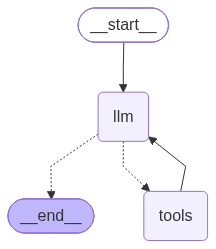

In [23]:
# ---- LLM Node ----
llm = ChatOpenAI(
    model="xiaomi/mimo-v2.5",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
)

# Add tools to the LLM, including the ones from MCPs
tools = [update_requirements, *ticketlens_tools, *weather_tools, *trvl_tool, rental_cars_tool]
llm_with_tools = llm.bind_tools(tools)

async def llm_node(state: TravelState) -> dict:
    # Extract the current requirements from the state
    current_requirements = state["requirements"]
    requirements_context = SystemMessage(
        content=f"""
Current travel requirements:

{current_requirements}
"""
    )

    # Add the current requirements to the system prompt + messages
    messages = [
        SystemMessage(content=SYSTEM_PROMPT),
        requirements_context, 
        *sanitize_messages_for_llm(state["messages"]),
    ]

    response = await llm_with_tools.ainvoke(messages)

    return {"messages": [response]}

# ---- Graph Builder ----
# Add short-term memory checkpointing
checkpointer = InMemorySaver()

builder = StateGraph(TravelState)

builder.add_node("llm", llm_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", tools_condition)
builder.add_edge("tools", "llm")

graph = builder.compile(checkpointer=checkpointer)

display(Image(graph.get_graph().draw_mermaid_png()))

## Test with different prompts

In [24]:
async def test_prompt(prompt):
    config = {"configurable": {"thread_id": str(uuid.uuid4())}}

    result = await graph.ainvoke({
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "requirements": None
    }, config)

    response = result["messages"][-1].content
    display(Markdown(response))

    return result

**Important**: After every test, verify the agent's traces with [LangSmith](https://smith.langchain.com) for ensuring that the agent is using the correct tools with appropriate parameters.

### 1. Activities MCP

In [20]:
# Test search_pois tool
prompt1 = "I'm planning a trip to Paris. Can you find the main points of " \
    "interest around the Eiffel Tower?"
test1 = await test_prompt(prompt1)

Based on my search for tours and general knowledge, here are the main points of interest around the Eiffel Tower in Paris:

**Immediate Vicinity:**
- **Champ de Mars** - The large public greenspace directly in front of the Eiffel Tower, perfect for picnics and photos
- **Trocadéro & Jardins du Trocadéro** - Across the Seine, offers the most iconic viewpoint of the Eiffel Tower
- **Palais de Chaillot** - Historic building at Trocadéro with excellent viewing platforms

**Nearby Attractions:**
- **Seine River** - River cruises depart from nearby docks (many tours combine Eiffel Tower with Seine cruises)
- **Musée du Quai Branly - Jacques Chirac** - Indigenous art museum just a short walk away
- **Invalides & Musée de l'Armée** - The golden-domed building is visible from the tower and contains Napoleon's tomb

**Dining & Experiences:**
- **Madame Brasserie** - Restaurant located within the Eiffel Tower itself (I found several tour options for dining here)
- **Picnic on Champ de Mars** - Popular with both tourists and locals

**Additional Considerations:**
- The area is well-connected by metro (Bir-Hakeim, Trocadéro stations)
- Evening visits offer spectacular views of Paris illuminated
- Many combination tours include Eiffel Tower access with other Paris highlights

To help you plan more effectively, could you share:
1. When are you planning to visit? (dates or general season)
2. How long do you want to spend in Paris?
3. Any particular interests beyond sightseeing? (art, history, food, etc.)
4. Budget range for activities?
5. Will you be traveling alone or with others?

This information will help me provide more tailored recommendations and find specific tours or experiences that match your preferences.

In [21]:
test1["requirements"]

TravelRequirements(origin=None, destination='Paris, France', travel_dates=None, duration_days=None, travelers=None, budget=None, currency=None, interests=[], constraints=[])

**Good response**: Checking LangSmith traces, the agent called `search_pois` and `search_tours` later. 

In [23]:
# Test search_tours tool
prompt2 = "I'm going to Paris and I'm interested in guided tours or experiences" \
    " related to the Eiffel Tower. What options can you find?"
test2 = await test_prompt(prompt2)

Based on your interest in Eiffel Tower guided tours in Paris, I found several options. Here are some of the top-rated tours:

## Top Eiffel Tower Guided Tours

1. **Paris: Eiffel Tower Guided Tour and Seine River Cruise**
   - Price: €69 (approx $67 USD, £50 GBP)
   - Rating: 4.5/5 (241 reviews)
   - Combines tower access with a river cruise
   - First available: August 26, 2026

2. **Paris: Eiffel Tower Guided Tour by Elevator**
   - Price: €53 (approx $63 USD, £46 GBP)
   - Rating: 4.3/5 (43 reviews)
   - Focuses on elevator access to the tower
   - First available: August 25, 2026

3. **Eiffel Tower Paris: Official guided tour in virtual reality**
   - Price: €29 (approx $33 USD, £25 GBP)
   - Rating: 4.9/5 (151 reviews) - Highest rated!
   - Unique virtual reality experience at the tower
   - First available: August 25, 2026

4. **Paris: Eiffel Tower Fully Guided Tour with Summit Option**
   - Price: €50 (approx $58 USD, £43 GBP)
   - Rating: 4.3/5 (833 reviews) - Most reviewed!
   - Offers option to visit the summit
   - First available: August 25, 2026

5. **Paris: Eiffel Tower Summit Small-Group Guided Tour Max 6 People**
   - Price: €116 (approx $138 USD, £101 GBP)
   - Rating: 4.95/5 (124 reviews) - Premium small-group experience
   - Limited to 6 people for more personalized attention
   - First available: August 25, 2026

There are also combination tours that include other Paris attractions like Versailles Palace or the Louvre, as well as full-day tours covering multiple sites.

**To help you choose the best option, could you tell me:**
- Do you have specific travel dates in mind?
- What's your budget range for this experience?
- Would you prefer a private tour or are you comfortable in a group setting?
- Are you interested in summit access or would a second-floor view be sufficient?

You can also click on any of the tour links above for more detailed information about inclusions, schedules, and what's covered in each tour.

The agent correctly used the `search_tours` tool and returned precise results for different tours.

In [24]:
# Test get_tour tool
prompt3 = "Find me a tour in Paris related to the Eiffel Tower and then give me more details about one of the available options."
test3 = await test_prompt(prompt3)

I found several Eiffel Tower tours in Paris! Here's an overview of the available options, followed by detailed information about one of the most popular choices:

---

## 🗼 Available Eiffel Tower Tours in Paris

| # | Tour | Price (EUR) | Rating | Reviews |
|---|------|-------------|--------|---------|
| 1 | Eiffel Tower: Official guided tour in virtual reality | €29 | ⭐ 4.93 | 151 |
| 2 | Eiffel Tower & Parisian Bridges Private Photo Tour | €155 | ⭐ 3.00 | 1 |
| 3 | **Eiffel Tower Access by Elevator & Seine River Cruise** | **€69** | **⭐ 4.56** | **7,642** |
| 4 | Early Evening Dinner at Madame Brasserie | €129.80 | ⭐ 4.46 | 1,683 |
| 5 | Stairs Climb to Level 2 & Summit Option | €39 | ⭐ 4.22 | 9,812 |
| 6 | Summit or Second Floor Access | €51.62 | ⭐ 4.42 | 17,092 |
| 7 | Eiffel Tower Tour & Seine River Cruise Tour | €66 | ⭐ 4.27 | 291 |
| 8 | Madame Brasserie 3-Course Lunch | €70.80 | ⭐ 4.31 | 2,611 |
| 9 | Fully Guided Tour with Summit Option | €50 | ⭐ 4.30 | 833 |
| 10 | E-Bike Night Tour (Eiffel Tower & Notre Dame) | €99 | ⭐ 4.94 | 16 |

---

## 🏆 Detailed Tour: Paris: Eiffel Tower Access by Elevator & Seine River Cruise

This is one of the best-rated combo tours with over 7,600 reviews!

### 💰 Price
- **€69** (~$80 USD / ~£59 GBP / ~65 CHF)

### ⭐ Rating
- **4.56/5** from 7,642 reviews

### 📋 What's Included
- ✅ Reserved entry to the 1st and 2nd floor of the Eiffel Tower
- ✅ Standard access to the summit (optional upgrade)
- ✅ 1-hour Seine River cruise
- ✅ Skip-the-line access
- ✅ English-speaking guide intro commentary
- ✅ Unlimited time inside the Eiffel Tower

### ❌ Not Included
- Gratuities
- Transfers
- Food and drink

### 📍 Meeting Point
**Agency at 41 Avenue de la Bourdonnais, 75007 Paris**
- Office hours: 08:30 – 18:30, daily

### 🚢 Cruise Schedule
- **October – March:** Departures every hour (10:00 – 21:30)
- **April – September:** Departures every 30 minutes (10:00 – 21:30)

### ⚠️ Important Information
- Arrive 15 minutes before your chosen time slot
- Children under 3 enter free (with valid ID)
- No large luggage allowed (no storage available)
- Summit may close due to weather/maintenance
- Not wheelchair accessible
- Cruise tickets valid for 6 months after your Eiffel Tower visit

---

**Would you like me to:**
1. Search for more specific tour types (e.g., private tours, food tours, photography tours)?
2. Help you plan the rest of your Paris trip?
3. Get more details on any other tour from the list?

The agent answered successfully the user's request. First, it called `search_tools` and then `get_tour` for getting detailed information about the best tour.

### 2. Weather MCP

In [ ]:
# Test forecast research
prompt4 = "I'm planning a 7-day trip to Paris for the next week. What weather " \
    "conditions should I expect during the trip, and are there any days that look " \
    "particularly good for outdoor activities?"
test4 = await test_prompt(prompt4)

Based on the weather forecast for Paris over the next 7 days (August 25–31, 2026), here’s what you can expect:

### **Daily Weather Summary**
| Date       | Max Temp | Min Temp | Precipitation | Wind Speed | Weather Conditions | UV Index | Sunrise/Sunset |
|------------|----------|----------|---------------|------------|---------------------|----------|----------------|
| **Aug 25** | 29°C     | 17°C     | 2.6 mm        | 12.6 km/h  | Light rain showers (WMO 80) | 5.9 (High) | 06:57 – 20:47 |
| **Aug 26** | 29.5°C   | 19.8°C   | 0.1 mm        | 10.9 km/h  | Light rain showers (WMO 80) | 5.8 (High) | 06:59 – 20:45 |
| **Aug 27** | 26.2°C   | 20.3°C   | 1.2 mm        | 14 km/h    | Light rain showers (WMO 80) | 4.7 (Moderate) | 07:00 – 20:43 |
| **Aug 28** | 23.3°C   | 17.4°C   | 0.3 mm        | 21.5 km/h  | Overcast (WMO 3) | 5.5 (Moderate) | 07:01 – 20:41 |
| **Aug 29** | 26.3°C   | 17.8°C   | 3.6 mm        | 30.8 km/h  | Light rain (WMO 61) | 1.9 (Low) | 07:03 – 20:39 |
| **Aug 30** | 25.3°C   | 17.3°C   | 0 mm          | 22.4 km/h  | Overcast (WMO 3) | 4.9 (Moderate) | 07:04 – 20:37 |
| **Aug 31** | 24.5°C   | 15.5°C   | 0 mm          | 18.9 km/h  | Overcast (WMO 3) | 3.2 (Moderate) | 07:06 – 20:35 |

**Key observations:**
- **Warm temperatures:** Highs in the mid‑20s°C (70s–80s°F), lows around 17–20°C (60s–68°F).
- **Mixed precipitation:** A few days have light rain showers or steady light rain; other days are dry.
- **Wind:** Generally breezy, with stronger gusts on August 28–30.
- **Daylight:** Long days (~13.5–14 hours), with sunrise around 07:00 and sunset after 20:30.

### **Best Days for Outdoor Activities**
1. **August 26** – Driest day (0.1 mm precipitation), warmest high (29.5°C), light winds, and strong sunshine (UV 5.8). Ideal for walking tours, picnics in parks, or outdoor dining.
2. **August 30** – No rain, moderate temperature (25.3°C), but overcast and windy. Suitable for sightseeing if you don’t mind clouds and wind.
3. **August 31** – Dry and slightly cooler (24.5°C), with lighter wind than the previous day. Good for outdoor exploration.

### **Days to Watch**
- **August 29** is the wettest (3.6 mm) and windiest (30.8 km/h), with low UV. Consider indoor activities (museums, cafés) on that day.
- **August 25 and 27** have light showers but are still warm; you can plan flexible outdoor plans with a rain jacket.

### **Recommendations**
- Pack light, breathable clothing, a waterproof layer, and comfortable walking shoes.
- Use sunscreen and sunglasses—UV levels are moderate to high on most days.
- Check the forecast again closer to your trip for any updates.

Would you like me to suggest specific outdoor activities or attractions in Paris based on these weather conditions?

The agent gave a correct response to the user's request using `openmeteo_search_locations` and `openmeteo_get_forecast`.

In [ ]:
# Test marine forecasting
prompt5 = "I'm considering a beach trip to Barcelona. Check the weather and marine " \
    "conditions and tell me whether the conditions look suitable for spending time at the beach."
test5 = await test_prompt(prompt5)

Based on the weather and marine forecast for Barcelona over the next 7 days (August 25–31, 2026), **conditions look generally suitable for a beach trip**, though there are a few factors to keep in mind.

### ☀️ Weather Summary
- **Temperatures:** Warm, with highs of **29–33°C (84–91°F)** and lows of **20–25°C (68–77°F)**. Ideal for sunbathing and swimming.
- **Precipitation:** Virtually **no rain** expected (only 0.1 mm on August 25).
- **Wind:** Moderate breeze, with gusts up to **21 km/h (13 mph)**. Might feel breezy on the beach but not strong enough to disrupt plans.
- **UV Index:** High, reaching **5–7** daily. Sunscreen and shade are recommended, especially midday.
- **Cloud Cover:** Varies from clear to partly cloudy, with some mornings overcast. Expect sunny afternoons.

### 🌊 Marine Conditions
- **Wave Heights:** Generally **calm to moderate**, ranging from **0.1–1.1 m (0.3–3.6 ft)**. Most days have waves under 1 m, suitable for swimming and paddling.
- **Swell Heights:** Also low, mostly **0.1–0.9 m**, so no large swell.
- **Wave Period:** Short (3–5 seconds), meaning the sea may feel a bit choppy rather than smooth.
- **Sea State:** Safe for swimming, but with moderate chop. August 28 has the highest waves (~1.06 m), still within safe limits for most beachgoers.

### 📅 Day-by-Day Outlook
| Date | High Temp | Precip | Max Wind | Max Wave | Notes |
|------|-----------|--------|----------|----------|-------|
| Aug 25 | 33°C | 0.1 mm | 21 km/h | 0.86 m | Warm, breezy, small waves |
| Aug 26 | 30°C | 0 mm | 11 km/h | 0.76 m | Calmer wind, waves decreasing |
| Aug 27 | 31°C | 0 mm | 20 km/h | 0.80 m | Similar to Aug 25 |
| Aug 28 | 31°C | 0 mm | 21 km/h | **1.06 m** | Highest waves of the week |
| Aug 29 | 29°C | 0 mm | 17 km/h | 0.80 m | Slightly cooler, moderate waves |
| Aug 30 | 31°C | 0 mm | 21 km/h | 0.28 m | Very calm sea |
| Aug 31 | 30°C | 0 mm | 14 km/h | 0.14 m | Extremely calm, ideal for swimming |

### ✅ Overall Assessment
**Yes, conditions look suitable for a beach trip.** You’ll enjoy warm, mostly dry weather with moderate sea conditions. The best days for calm swimming appear to be **August 30–31**, when waves drop below 0.3 m. Earlier in the week, waves are slightly higher but still safe for most swimmers.

**Recommendations:**
- Pack sunscreen (UV high).
- Bring a windbreaker for breezy afternoons.
- Check daily forecasts closer to your trip for any updates.
- If you prefer very calm water, aim for the latter half of the week.

Would you like help planning tours or activities in Barcelona that complement these beach conditions?

The agent gave a correct and accurate response to the user's request using `openmeteo_search_locations`, `openmeteo_get_forecast` and `openmeteo_get_marine` tools.

### 3. Hotel and Transportation MCP

In [30]:
# Hotels
prompt6 = "I'm going to Paris from September 10 to September 17, 2026. " \
    "Find suitable hotels for two people with a budget of €1,000 for the stay."
test6 = await test_prompt(prompt6)

I found several accommodation options in Paris for September 10-17, 2026 (7 nights) that fit your €1,000 budget for two people. Here are the three verified options within your budget:

## **Within Your Budget (€1,000 total)**

### 1. **ART hotel paris est** - €588 total
- **Type:** Entire apartment (studio)
- **Price:** €75.25/night → **€587.86 total** (taxes included)
- **Rating:** 6.6/10 (1,413 reviews)
- **Cancellation:** Non-refundable
- **Provider:** Agoda
- **Pros:** Most affordable option, apartment-style with kitchenette
- **Cons:** Lower rating, non-refundable

### 2. **Pullman Paris Tour Eiffel** - €861 total
- **Type:** Hotel room
- **Price:** €91.82/night → **€861 total** (taxes included)
- **Rating:** 9.2/10 (16,983 reviews)
- **Cancellation:** Available
- **Provider:** Agoda
- **Pros:** Excellent rating, 4-star hotel, great location near Eiffel Tower
- **Cons:** Slightly higher price but still within budget

### 3. **The People** - €861 total
- **Type:** Hostel bed (but private room available)
- **Price:** €91.82/night → **€861 total** (taxes included)
- **Rating:** 8.0/10 (1,893 reviews)
- **Cancellation:** Available
- **Provider:** Agoda
- **Pros:** Good rating, central location (17 Boulevard Morland)
- **Cons:** Hostel-style accommodation, price 39% higher than advertised lead-in

## **Over Budget**
- **Hotel Auteuil Tour Eiffel:** €1,742 total (4-star, 8.2 rating)
- **Nouvel Hotel Eiffel - Paris:** €2,270 total (3-star, 8.2 rating, free cancellation)

## **My Recommendation**
Given your budget and preferences for two people, I'd suggest the **Pullman Paris Tour Eiffel** as the best value. It offers:
- Excellent 9.2 rating with nearly 17,000 reviews
- Prime location near the Eiffel Tower
- Verified price of €861 total (well within your €1,000 budget)
- Standard hotel amenities

The **ART hotel** is the most economical if you want to save money for other expenses, while **The People** offers a good middle ground with a central location.

Would you like more details about any of these options, or should I search for specific neighborhoods or hotel types?

The agent succesfully called the `travel` tool using the `search_accommodations` intent with appropriate parameters.

In [31]:
# Flight Search
prompt7 = "Find me the cheapest realistic flight from Madrid to Paris for two people, " \
    "departing September 10, 2026 and returning September 17, 2026."
test7 = await test_prompt(prompt7)

I found 24 round-trip flights from Madrid (MAD) to Paris for 2 people, departing September 10, 2026 and returning September 17, 2026. Here are the most relevant options:

## 🏆 Cheapest Flight
**Transavia France** - **€117 per person** (€234 total for 2)
- **Outbound:** Sep 10, 06:00 → 08:05 (Madrid → Paris Orly)
- **Return:** Sep 17, 06:10 → 08:20 (Paris Orly → Madrid)
- **Duration:** ~2h 5m each way
- **Stops:** Nonstop
- **Booking:** [Skiplagged link](https://skiplagged.com/flights/MAD/ORY/2026-09-10/2026-09-17?utm_source=mcp&utm_medium=ai&utm_campaign=skiplagged_mcp#trip=TO4781,TO4630)

## Other Good Options
1. **Transavia France** - €122/person (€244 total)
   - Outbound: Sep 10, 13:30 → 15:40 → Return: Sep 17, 06:10 → 08:20
   - Nonstop, similar schedule but later departure

2. **Air France** - €130/person (€260 total) - *Bags included*
   - Outbound: Sep 10, 16:40 → 18:45 → Return: Sep 17, 07:00 → 09:10
   - Nonstop, arrives at Charles de Gaulle (CDG) instead of Orly

3. **Kiwi.com option** - €125/person (€250 total)
   - Same Transavia flights but booked through Kiwi with different baggage policies

## Important Considerations
1. **Airports:** Most cheap flights arrive at **Paris Orly (ORY)**, not Charles de Gaulle (CDG). Orly is closer to central Paris (~40 min by train).

2. **Baggage:** The cheapest Transavia fare likely doesn't include checked baggage. The Air France option at €130/person includes bags.

3. **Booking Window:** You're booking about 15 days in advance. For European short-haul, prices may increase as departure approaches.

4. **Total Cost:** Remember to factor in:
   - Airport transfers (~€10-17 per person)
   - Possible baggage fees if flying Transavia
   - Meals on board (budget airlines charge for food)

## Recommendation
For the **absolute cheapest price**, book the **Transavia €117/person** option, but be aware of potential extra costs for bags and meals. If you prefer a more comfortable experience with included bags, the **Air France €130/person** option offers better value overall.

Would you like me to:
1. Search for alternative dates that might be cheaper?
2. Look for accommodation in Paris for your stay?
3. Check airport transfer options from Orly to central Paris?

The agent succesfully called the `travel` tool using the `search_flights` intent with appropriate parameters. Then, it compared all the alternatives and offered the most relevant flight to the user.

In [37]:
# Train
prompt8 = "I'm planning a trip from Paris to Amsterdam. Find the best train options " \
    "for September 15, 2026."
test8 = await test_prompt(prompt8)

Here are the best train options for **Paris → Amsterdam on September 15, 2026**:

---

## 🚄 Direct Option (Recommended)

| Provider | Price | Duration | Route | Date |
|----------|-------|----------|-------|------|
| **Eurostar** | **€79** | 2h 15m | Paris Gare du Nord → Amsterdam Centraal | Sep 15 |

✅ **Direct, no transfers** — this is the best option for your date.  
🔗 [Book on Eurostar](https://www.eurostar.com/en/train-tickets?origin=8727100&destination=8400058&outbound=2026-09-15)

---

## 🔄 Alternative: With Transfers (Sep 15)

| Price | Duration | Transfers | Departure → Arrival |
|-------|----------|-----------|---------------------|
| N/A | 3h 50m | 2 | 08:39 → 12:29 |
| N/A | 3h 50m | 2 | 10:09 → 13:59 |
| N/A | 3h 50m | 2 | 12:09 → 15:59 |

These transitous options are slower, involve transfers, and have no pricing available — not recommended unless the Eurostar is sold out.

---

## 💡 Flexibility Tip

If your dates are flexible, prices drop significantly on nearby days:
- **Sep 19**: €35 (saves €44!)
- **Sep 16**: €65 (saves €14)

---

**My recommendation**: Book the **Eurostar at €79 for Sep 15**. It's direct, fast (2h 15m), and departs from Paris Gare du Nord (easy to reach via metro/RER). Would you like me to help with anything else for your Amsterdam trip — accommodations, activities, or weather info?

The agent succesfully called the `travel` tool using the `ground` intent with appropriate parameters. Then, it compared all the alternatives and offered the most relevant ones to the user.

In [ ]:
# Multimodal comparison
prompt9 = "Find the best way to travel from Madrid to Paris for two people, departing September 10, 2026 and returning September 17, 2026, considering " \
    "flights and other realistic transport options. Prioritize total travel time and price."
test9 = await test_prompt(prompt9)

Here's a comprehensive comparison of all transport options for **2 travelers, Madrid → Paris, Sept 10–17, 2026**:

---

## ✈️ Flights (Round-trip for 2 people)

| Option | Airline | Route | Outbound | Return | Total (2 pax) | Travel Time |
|--------|---------|-------|----------|--------|----------------|-------------|
| **🏆 Best Value** | Transavia | MAD↔ORY | 06:00→08:05 | 06:10→08:20 | **€234** | 2h05m each way |
| Full-Service | Air France | MAD↔CDG | 16:40→18:45 | 07:05→09:00 | ~€242 | 2h05m each way |
| Morning Option | Air France | MAD↔CDG | 12:20→14:25 | 06:50→09:00 | ~€248 | 2h05m each way |

> **Note:** Budget fares (Transavia) don't include checked bags. Add ~€25–40/bag if needed. Orly (ORY) is closer to central Paris than CDG.

---

## 🚌 Bus (FlixBus, one-way per person)

| Option | Departure | Arrival | Duration | Per Person | Total (2 pax) |
|--------|-----------|---------|----------|------------|----------------|
| **Cheapest Direct** | 16:40 | 09:00+1 | 16h20m | €35 | **€70** |
| Direct | 14:50 | 07:15+1 | 16h25m | €36 | €72 |
| Evening Direct | 20:25 | 12:30+1 | 16h05m | €40 | €80 |

> Round-trip estimate for bus: **~€140–160 total** for 2 people.

---

## 🚆 Train (via Barcelona)

| Route | Duration | Transfers | Price |
|-------|----------|-----------|-------|
| Madrid → Barcelona (AVE) → Paris (TGV) | **~11 hours** | 3 | Price unavailable |

> The train takes **~11 hours** total via Barcelona (high-speed AVE + TGV). No direct Madrid–Paris high-speed service exists yet. Prices typically range **€100–200+ per person** one-way when booked in advance, making it the most expensive option.

---

## 📊 Summary Comparison (2 people, round-trip)

| Mode | Total Cost (2 pax) | Total Travel Time (both ways) | Comfort |
|------|-------------------|-------------------------------|---------|
| 🚌 **Bus** | **~€140–160** | ~32–33 hours | Low (overnight) |
| ✈️ **Flight** | **~€234–266** | ~4 hours | Medium-High |
| 🚆 **Train** | **~€400–800+** | ~22 hours | High |

---

## 🏆 My Recommendation

**Flights are clearly the best option** when balancing travel time and price:

- **Transavia MAD→ORY at €234 total** for 2 is only ~€80 more than the bus, but saves you **~28 hours of travel time** (3h vs 33h round-trip)
- Orly airport is well-connected to central Paris (Orlyval + RER, ~€10/person, ~40 min)
- You arrive fresh and ready to enjoy your 7-day trip instead of losing 1.5 days to buses

**If budget is the absolute priority**, the overnight bus is viable — you'd save ~€80–120 but arrive exhausted after 16+ hours on a coach.

**If comfort is paramount**, train via Barcelona is scenic but expensive and slower than flying.

Would you like me to search for accommodations in Paris for your dates, or dig deeper into any of these options?

The agent correctly compared different transportation option recovered from the trvl MCP. It used the flight intent and the ground intent specifying the types train and bus in params.

### 4. Rental Cars MCP

In [29]:
# Car style preferences
prompt10 = "Find me a sporty car to rent in Madrid Airport from September 10 to September 12, 2026."
test10 = await test_prompt(prompt10)

I found 32 rental car options at Madrid Airport for September 10-12, 2026. Since you're looking for a "sporty car," here are some potential sporty options from the results:

**Most sporty options:**
1. **Cupra Formentor** (Centauro) - Automatic, intermediate category, €53.10 total (€26.55/day). The Formentor is a sporty compact SUV from Cupra (Seat's performance brand).

2. **BMW 1 Series** (Ok Mobility) - Automatic, compact elite category, €129.31 total (€64.66/day). BMW's signature sporty hatchback.

3. **Mini Cooper** (Click&Rent) - Automatic, economy elite category, €57.56 total (€28.78/day). Known for its sporty handling and go-kart feel.

4. **Alfa Romeo Stelvio** (Record go) - Automatic, premium category, €132.09 total (€66.05/day). Italian luxury SUV with sporty performance.

5. **Audi A5** (Europcar) - Automatic, luxury category, €322.02 total (€161.01/day). Premium sporty sedan/coupe.

6. **Audi A6** (SIXT) - Automatic, luxury category, €354.32 total (€177.16/day). Larger luxury sedan with sporty options.

**Other considerations:**
- Most sporty cars come with automatic transmission
- Prices range from €53 to €354 for 2 days
- All include basic protections (collision, theft, etc.)
- Mileage varies (400-700 km included)

To help narrow down the best match, could you tell me:
1. Do you prioritize performance/handling, brand prestige, or sporty looks?
2. Any preference for automatic vs. manual transmission?
3. What's your budget range?
4. Do you need a specific size (compact vs. larger)?

I can also search for more specific categories or brands if you have particular preferences.

In [30]:
# Price and age restrictions
prompt11 = "Find a cheap rental car at Lanzarote Airport from September 10 to September 17, 2026." \
    "The driver is 25 years old."
test11 = await test_prompt(prompt11)

I found 22 rental car options at Lanzarote Airport for **September 10–17, 2026** (7 days). Here are the cheapest deals:

## Top 3 cheapest options:

1. **Fiat 500 (Mini)** – **€50.29 total** (€7.18/day)
   - Vendor: Record go
   - Manual transmission, 4 passengers, **no air conditioning**
   - Deposit: €1,100
   - Unlimited mileage, free cancellation & amendment

2. **Hyundai i10 (Mini)** – **€50.88 total** (€7.27/day)
   - Vendor: Record go
   - Manual transmission, 5 passengers, **with air conditioning**
   - Deposit: €1,100
   - Unlimited mileage, free cancellation & amendment

3. **Kia Rio (Economy)** – **€53.85 total** (€7.69/day)
   - Vendor: Record go
   - Manual transmission, 5 passengers, air conditioning
   - Deposit: €1,100
   - Unlimited mileage, free cancellation & amendment

All prices are in EUR and include collision damage waiver, theft protection, VAT, and airport surcharge. The driver age of 25 is acceptable for all offers.

**Other observations:**
- Most vehicles are manual transmission.
- Deposits range from €920 to €2,000.
- The cheapest option with air conditioning is the Hyundai i10 at €50.88.

Would you like to see more details on any of these, or should I filter by specific criteria (e.g., automatic transmission, air conditioning, lower deposit)?

The agent used the `search_rental_cars` tool and gave good responses adjusting to the user's preferences and constraints.